# Plot scientific interest for one pathogen–antibiotic pair

This notebook uses saved SI when the pair is available. Otherwise, its recovery helper searches the cached screened counts, candidate-year PMID lists, candidate pair-PMID links, and cached screening decisions. It rebuilds pair counts when possible, refits the pooled SI baseline for that pair, and reports counts found at each stage. The result is exploratory and does not change canonical outputs.

If only raw candidate mentions remain, `PAIR_ALLOW_CANDIDATE_PROXY` can still produce a clearly marked candidate-only figure. Its residual is not an AMR scientific-interest estimate.

Change `PATHOGEN` and `ANTIBIOTIC` in the selection cell.


In [1]:
from pathlib import Path
import sys
import importlib

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.si import build_si_analysis_paths
single_pair_si_module = importlib.import_module("amr.pipelines.single_pair_si")
single_pair_si_module = importlib.reload(single_pair_si_module)
plot_single_pair_si = single_pair_si_module.plot_single_pair_si

PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)
ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level", "antibiotic")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANALYSIS_LEVEL)
SI_PATH = SI_PATHS["yearly_si"]
PATHOGEN_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT) / "single_pair_si_plots"

if not SI_PATH.exists():
    raise FileNotFoundError(f"Missing reference SI dataset {SI_PATH}. Run notebook 05_model_scientific_interest.ipynb first.")
si_df = pd.read_parquet(SI_PATH)
pathogen_background_df = pd.read_parquet(PATHOGEN_BACKGROUND_PATH)
antibiotic_background_df = pd.read_parquet(ANTIBIOTIC_BACKGROUND_PATH)
print(f"Loaded {len(si_df):,} reference SI rows from {SI_PATH}")


Loaded 18,455 reference SI rows from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet


In [2]:
# Find available names by entering any part of a pathogen or antibiotic name.
def _print_compatible_names(query, values, label):
    query = str(query).strip().casefold()
    matches = sorted(
        {str(value) for value in values.dropna() if query in str(value).casefold()},
        key=str.casefold,
    ) if query else []
    print(f"{label} matches for {query!r} ({len(matches)}):")
    for name in matches:
        print(f"- {name}")
    return matches

def find_pathogens(letters):
    """Print pathogen names containing the supplied letters (case-insensitive)."""
    return _print_compatible_names(letters, pathogen_background_df["pathogen"], "Pathogen")

def find_antibiotics(letters):
    """Print antibiotic names containing the supplied letters (case-insensitive)."""
    return _print_compatible_names(letters, antibiotic_background_df["antibiotic"], "Antibiotic")

# Examples: find_pathogens("shigella"); find_antibiotics("trim")


In [3]:
_ = find_pathogens("aureus")

Pathogen matches for 'aureus' (1):
- Staphylococcus aureus


In [4]:
_ = find_antibiotics("sul")

Antibiotic matches for 'sul' (23):
- Ampicillin/sulbactam
- Cefsulodin
- Sulbactam
- Sulbenicillin
- Sulfadiazine
- Sulfadiazine/trimethoprim
- Sulfadimethoxine
- Sulfadimidine
- Sulfadimidine/trimethoprim
- Sulfafurazole
- Sulfamerazine
- Sulfamerazine/trimethoprim
- Sulfamethizole
- Sulfamethoxazole
- Sulfamethoxazole/trimethoprim
- Sulfamethoxypyridazine
- Sulfametrole/trimethoprim
- Sulfamoxole
- Sulfanilamide
- Sulfaphenazole
- Sulfapyridine
- Sulfathiazole
- Sultamicillin


In [5]:
def show_pathogen_amr_counts(pathogen):
    """Display antibiotics and summed yearly AMR counts for a pathogen in saved SI data."""
    pathogen_key = str(pathogen).strip().casefold()
    mask = si_df["pathogen"].astype(str).str.casefold().eq(pathogen_key)
    if not mask.any():
        result = pd.DataFrame(columns=["antibiotic", "amr_publications"])
        print(f"No saved SI rows found for pathogen {pathogen!r}.")
        display(result)
        return result

    result = (
        si_df.loc[mask].groupby("antibiotic", as_index=False)["count"]
        .sum()
        .rename(columns={"count": "amr_publications"})
        .sort_values("amr_publications", ascending=False)
        .reset_index(drop=True)
    )
    print(f"Antibiotic pairs for {pathogen!r} (summed across saved SI years):")
    display(result)
    return result

# Example: show_pathogen_amr_counts("Streptococcus pneumoniae")
res_df = show_pathogen_amr_counts("Streptococcus pneumoniae")


Antibiotic pairs for 'Streptococcus pneumoniae' (summed across saved SI years):


,antibiotic,amr_publications
0,Erythromycin,1226
1,Levofloxacin,679
2,Ceftriaxone,595
3,Tetracycline,528
4,Amoxicillin,522
5,Cefotaxime,461
6,Trimethoprim,436
7,Sulfamethoxazole,436
8,Sulfamethoxazole/trimethoprim,426
9,Clindamycin,387


In [6]:
res_df['antibiotic'].values.tolist()

['Erythromycin',
 'Levofloxacin',
 'Ceftriaxone',
 'Tetracycline',
 'Amoxicillin',
 'Cefotaxime',
 'Trimethoprim',
 'Sulfamethoxazole',
 'Sulfamethoxazole/trimethoprim',
 'Clindamycin',
 'Ciprofloxacin',
 'Azithromycin',
 'Vancomycin',
 'Moxifloxacin',
 'Chloramphenicol',
 'Clarithromycin',
 'Telithromycin',
 'Benzylpenicillin',
 'Linezolid',
 'Cefuroxime',
 'Gatifloxacin',
 'Ampicillin',
 'Meropenem',
 'Ofloxacin',
 'Gemifloxacin',
 'Amoxicillin/clavulanic-acid',
 'Rifampicin',
 'Cefaclor',
 'Tigecycline',
 'Trovafloxacin',
 'Oxacillin',
 'Cefdinir',
 'Cefepime',
 'Dalfopristin/quinupristin',
 'Doxycycline',
 'Garenoxacin',
 'Panipenem',
 'Sparfloxacin',
 'Ceftaroline-fosamil']

Loaded 18,455 reference SI rows from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet


,year,candidate_count,stored_screened_count,recomputed_screened_count
0,2000,4,4,<NA>
1,2001,3,3,<NA>
2,2002,4,3,<NA>
3,2003,4,2,<NA>
4,2004,4,4,<NA>
5,2005,2,2,<NA>
6,2006,3,3,<NA>
7,2007,4,3,<NA>
8,2008,2,2,<NA>
9,2009,1,1,<NA>


Recovered from: stored yearly_amr_screened_pairs.parquet (candidate_amr_pair_year_counts.parquet)
Interpretation: screened_amr


,year,count,count_for_model,SI
0,2000,4,4.0,0.139674
1,2001,3,3.0,0.029756
2,2002,3,3.0,-0.027674
3,2003,2,2.0,-0.081128
4,2004,4,4.0,0.154785
5,2005,2,2.0,-0.122732
6,2006,3,3.0,0.059952
7,2007,3,3.0,0.060875
8,2008,2,2.0,-0.082309
9,2009,1,1.0,-0.238016


Saved plot to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/single_pair_si_plots/Streptococcus_pneumoniae__Panipenem.pdf
Fit: 2000–2025; forecast extension: 5 years; valid training years: 16; SI mode: screened_amr


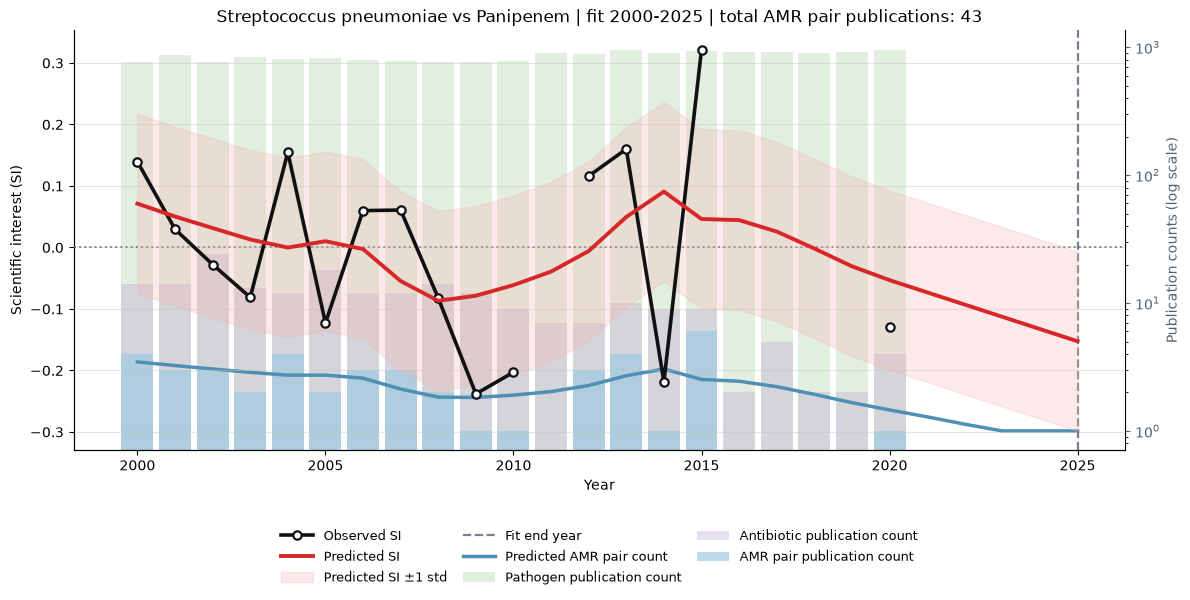

Generated 1 plot(s); skipped 0 unavailable pair(s).


In [7]:
# Edit these lists; every pathogen-antibiotic combination is plotted when data is available.
PATHOGENS = ["Streptococcus pneumoniae"]
ANTIBIOTICS = ["Panipenem"]

# If the selected pair is missing or too sparse in saved SI, recover it from cached
# upstream tables. Optional overrides relax only this pair's screening decision.
RECOMPUTE_PAIR_IF_MISSING = True
PAIR_RECOMPUTE_MIN_AMR_PUBLICATION_COUNT = 1.0
PAIR_SYSTEM1_PROBABILITY_THRESHOLD = None
PAIR_LLM_INCLUDE_DECISIONS = None
PAIR_ALLOW_CANDIDATE_PROXY = True

PAIR_PLOT_RESULTS = plot_single_pair_si(
    PATHOGENS,
    ANTIBIOTICS,
    recompute_pair_if_missing=RECOMPUTE_PAIR_IF_MISSING,
    pair_recompute_min_amr_publication_count=PAIR_RECOMPUTE_MIN_AMR_PUBLICATION_COUNT,
    pair_system1_probability_threshold=PAIR_SYSTEM1_PROBABILITY_THRESHOLD,
    pair_llm_include_decisions=PAIR_LLM_INCLUDE_DECISIONS,
    pair_allow_candidate_proxy=PAIR_ALLOW_CANDIDATE_PROXY,
    project_root=PROJECT_ROOT,
)
